In [ ]:
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

In [ ]:
# Fetch the Heart Disease dataset from UCI using its uci repository ID (45)
heart_disease = fetch_ucirepo(id=45)

# Extract the feature data (input features)
X = heart_disease.data.features

# Extract the target (output variable)
y = heart_disease.data.targets

# Combine features and target into a single DataFrame
df = pd.concat([X, y], axis=1)

df.head()

In [ ]:
print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

In [ ]:
df.info()

In [ ]:
df.isnull().sum()

In [ ]:
df["num"].value_counts().sort_index()

In [ ]:
df.describe()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="num")

plt.title("Distribution of Heart Disease Target (Original)")
plt.xlabel("Heart Disease Level (num)")
plt.ylabel("Number of Patients")

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Frequency")

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="chol", bins=20, kde=True)

plt.title("Cholesterol Distribution")
plt.xlabel("Serum Cholesterol (mg/dl)")
plt.ylabel("Frequency")

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="trestbps", bins=20, kde=True)

plt.title("Resting Blood Pressure Distribution")
plt.xlabel("Resting Blood Pressure (mm Hg)")
plt.ylabel("Frequency")

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="thalach", bins=20, kde=True)

plt.title("Maximum Heart Rate Distribution")
plt.xlabel("Maximum Heart Rate Achieved")
plt.ylabel("Frequency")

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="oldpeak", bins=20, kde=True)

plt.title("Oldpeak Distribution")
plt.xlabel("Oldpeak")
plt.ylabel("Frequency")

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="cp")

plt.title("Distribution of Chest Pain Types")
plt.xlabel("Chest Pain Type (cp)")
plt.ylabel("Number of Patients")

plt.show()

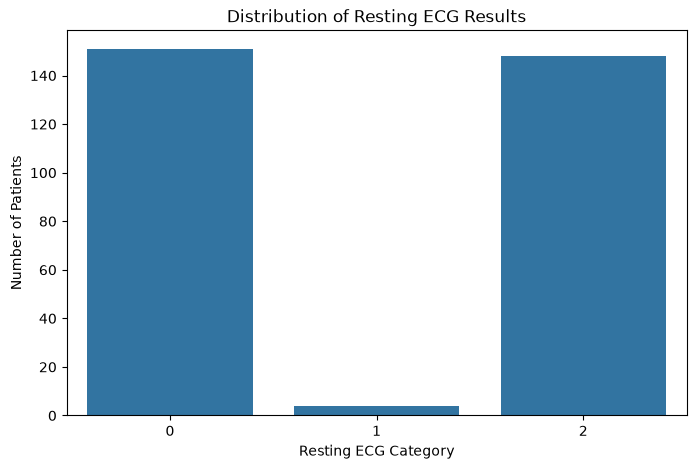

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="restecg")

plt.title("Distribution of Resting ECG Results")
plt.xlabel("Resting ECG Category")
plt.ylabel("Number of Patients")

plt.show()

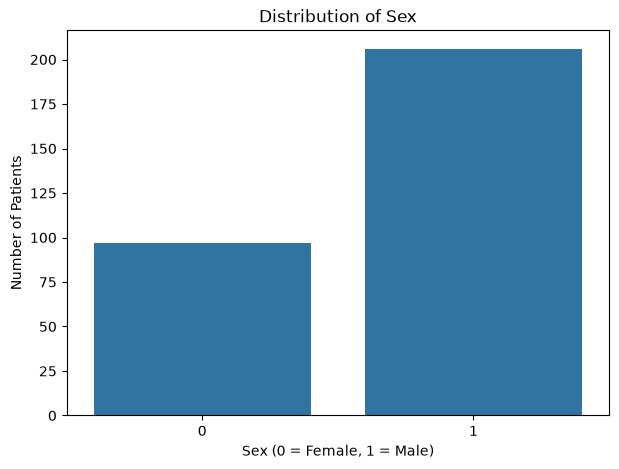

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex")

plt.title("Distribution of Sex")
plt.xlabel("Sex (0 = Female, 1 = Male)")
plt.ylabel("Number of Patients")

plt.show()

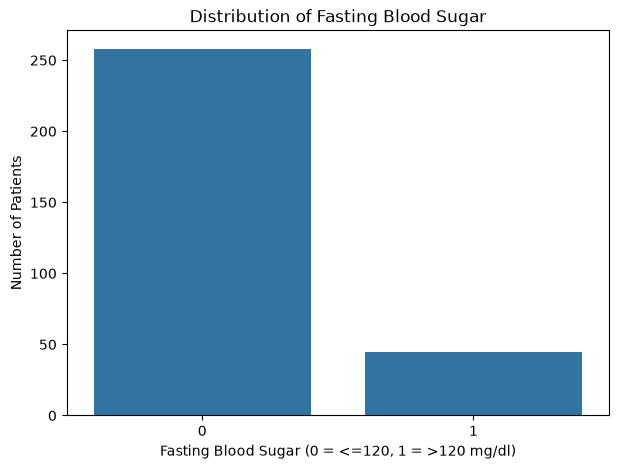

In [20]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="fbs")

plt.title("Distribution of Fasting Blood Sugar")
plt.xlabel("Fasting Blood Sugar (0 = <=120, 1 = >120 mg/dl)")
plt.ylabel("Number of Patients")

plt.show()

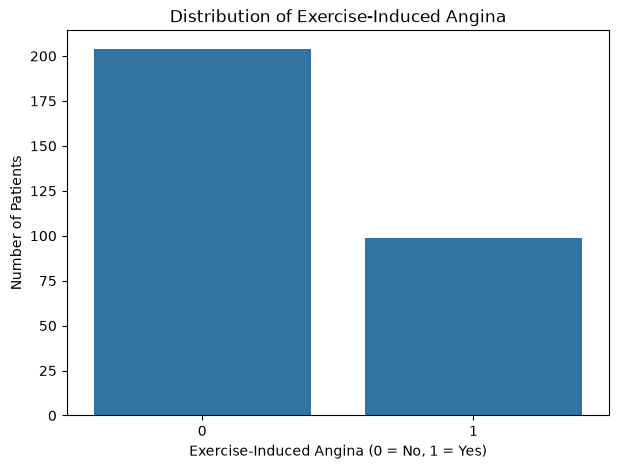

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="exang")

plt.title("Distribution of Exercise-Induced Angina")
plt.xlabel("Exercise-Induced Angina (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

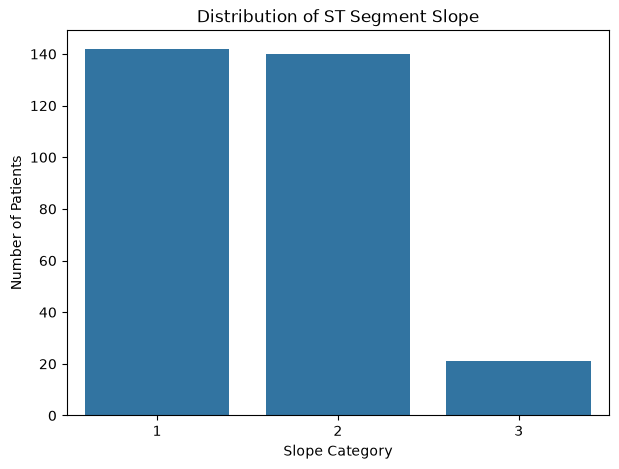

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="slope")

plt.title("Distribution of ST Segment Slope")
plt.xlabel("Slope Category")
plt.ylabel("Number of Patients")

plt.show()

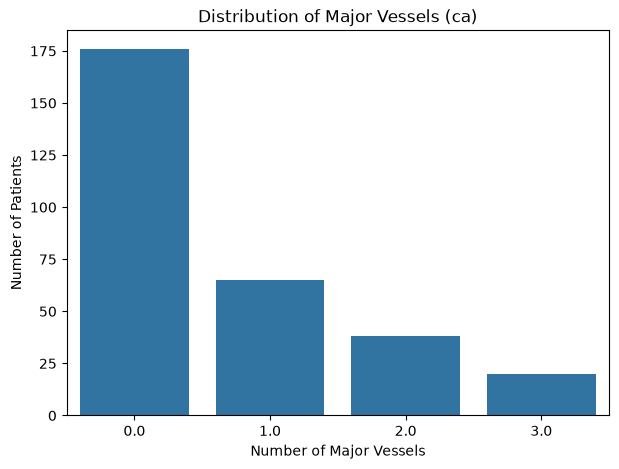

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="ca")

plt.title("Distribution of Major Vessels (ca)")
plt.xlabel("Number of Major Vessels")
plt.ylabel("Number of Patients")

plt.show()

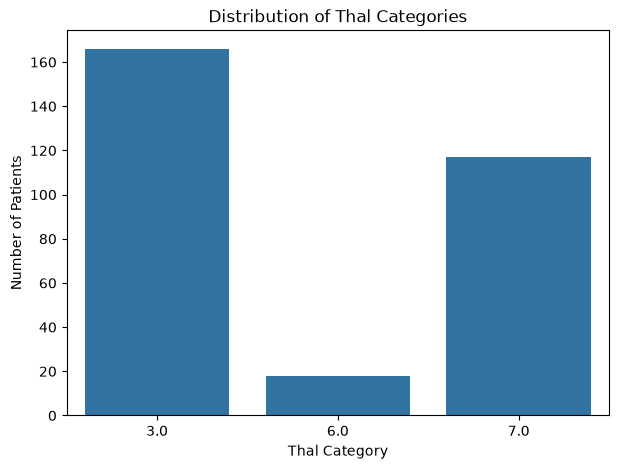

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="thal")

plt.title("Distribution of Thal Categories")
plt.xlabel("Thal Category")
plt.ylabel("Number of Patients")

plt.show()

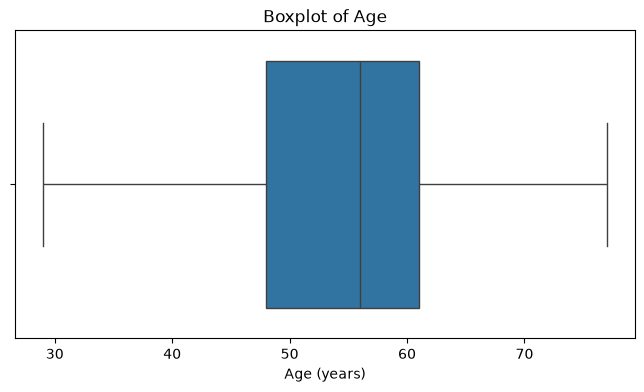

In [25]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="age")

plt.title("Boxplot of Age")
plt.xlabel("Age (years)")

plt.show()

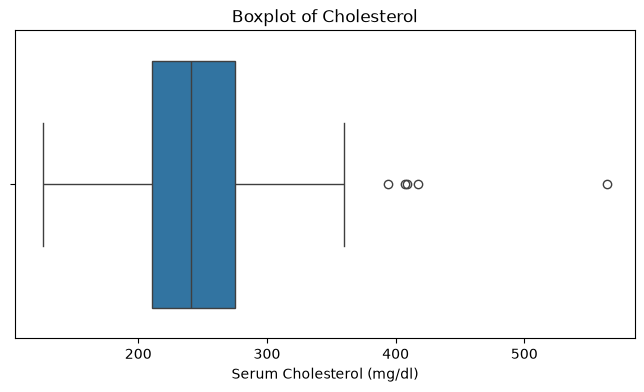

In [26]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="chol")

plt.title("Boxplot of Cholesterol")
plt.xlabel("Serum Cholesterol (mg/dl)")

plt.show()

Cholesterol outlier analysis: The boxplot identified several potential upper-side outliers in the chol feature. Using the IQR method, Q1 = 211 and Q3 = 275, resulting in an IQR of 64. The lower and upper boundaries are 115 and 371, respectively. Several observations exceed the upper boundary. These values will be retained at this stage because statistical outliers are not necessarily erroneous measurements.

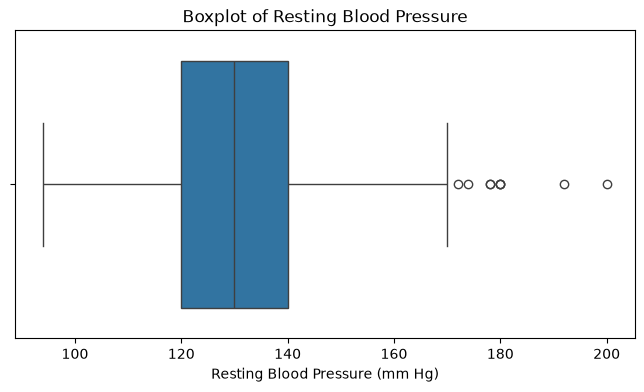

In [27]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="trestbps")

plt.title("Boxplot of Resting Blood Pressure")
plt.xlabel("Resting Blood Pressure (mm Hg)")

plt.show()

Resting blood pressure outlier analysis: The trestbps feature contains several potential upper-side outliers. Using Q1 = 120 and Q3 = 140, the IQR is 20, resulting in lower and upper bounds of 90 and 170 mm Hg. Several observations exceed the upper bound. These records will be retained because they may represent valid patient measurements.

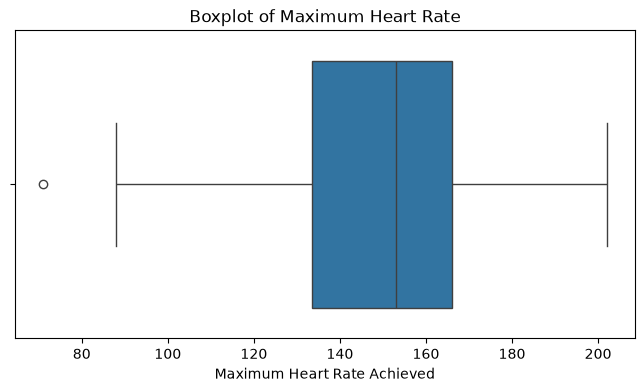

In [28]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="thalach")

plt.title("Boxplot of Maximum Heart Rate")
plt.xlabel("Maximum Heart Rate Achieved")

plt.show()

Maximum heart rate outlier analysis: The thalach feature contains one potential lower-side outlier. Using Q1 = 133.5 and Q3 = 166, the IQR is 32.5, giving lower and upper boundaries of 84.75 and 214.75 bpm. One observation at approximately 71 bpm falls below the lower boundary. This observation will be retained because it may represent a valid and informative patient measurement.

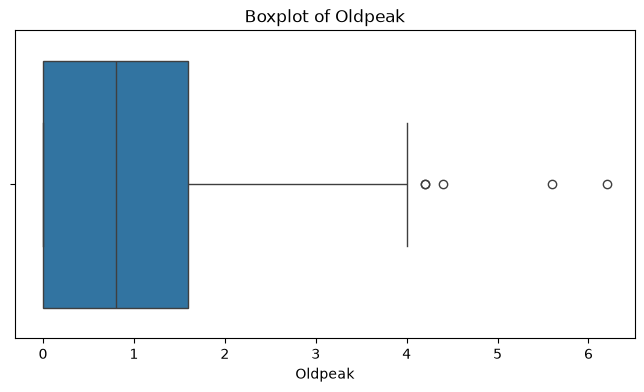

In [29]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="oldpeak")

plt.title("Boxplot of Oldpeak")
plt.xlabel("Oldpeak")

plt.show()

Oldpeak outlier analysis: The oldpeak feature contains four potential upper-side outliers. With Q1 = 0 and Q3 = 1.6, the IQR is 1.6 and the upper boundary is 4.0. Four observations exceed this boundary. These observations will be retained because they may represent meaningful clinical patterns rather than data errors.

In [30]:
# Convert the original target into a binary classification target
df["target"] = (df["num"] > 0).astype(int)

# Display the target distribution
print("Binary Target Distribution:")
print(df["target"].value_counts().sort_index())

print("\nTarget percentages:")
print((df["target"].value_counts(normalize=True).sort_index() * 100).round(2))

Binary Target Distribution:
target
0    164
1    139
Name: count, dtype: int64

Target percentages:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


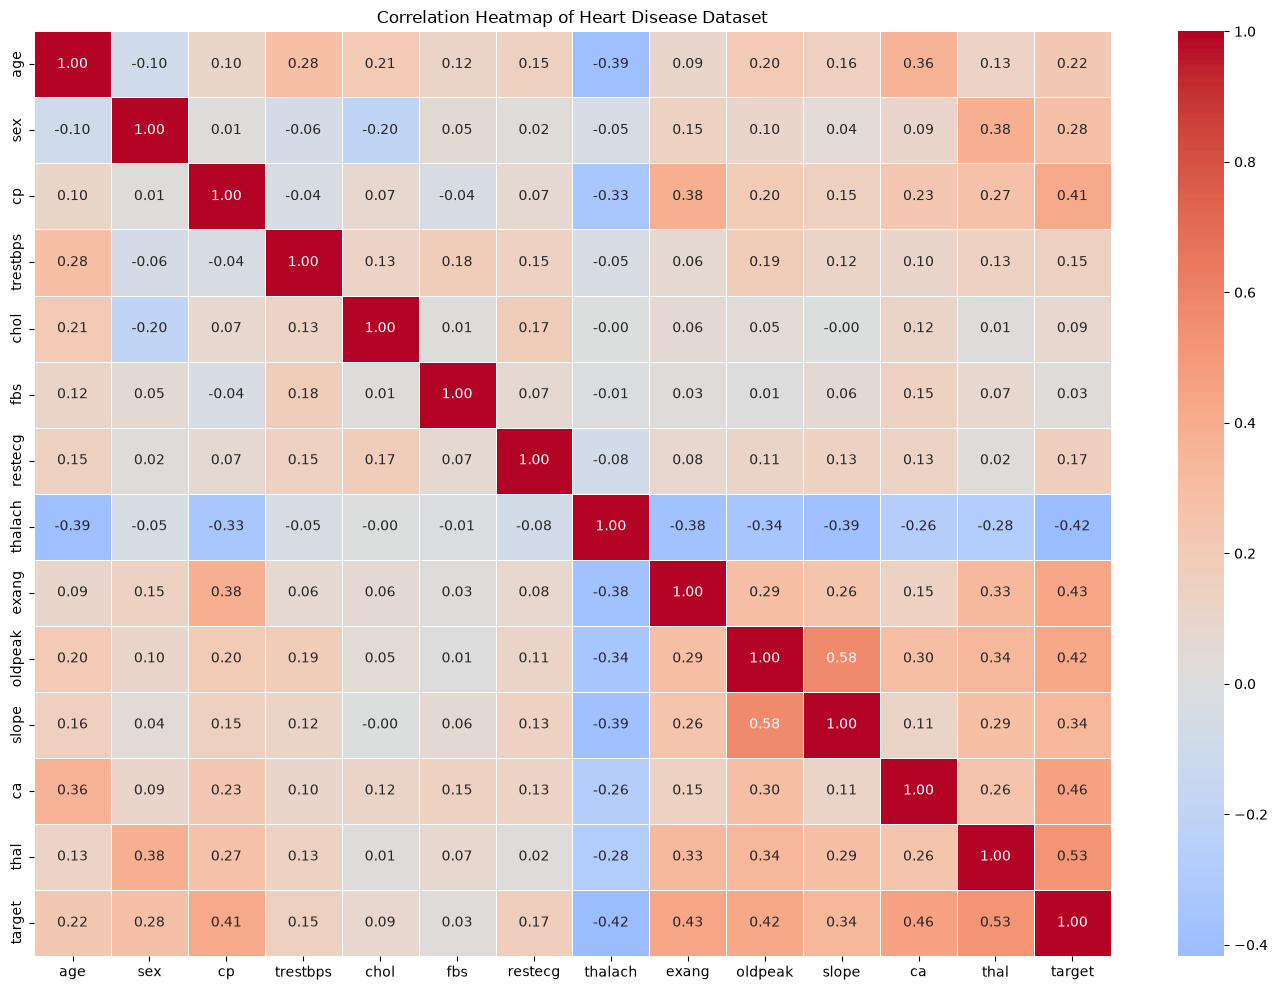

In [31]:
# Select features and the new binary target
# Exclude original 'num' because target is derived from it

corr_data = df.drop(columns=["num"])

# Calculate correlation matrix
correlation_matrix = corr_data.corr()

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Heart Disease Dataset")
plt.tight_layout()
plt.show()

This is an important EDA step because it gives us an overview of how features relate to each other and how each feature is linearly associated with our binary target, target.

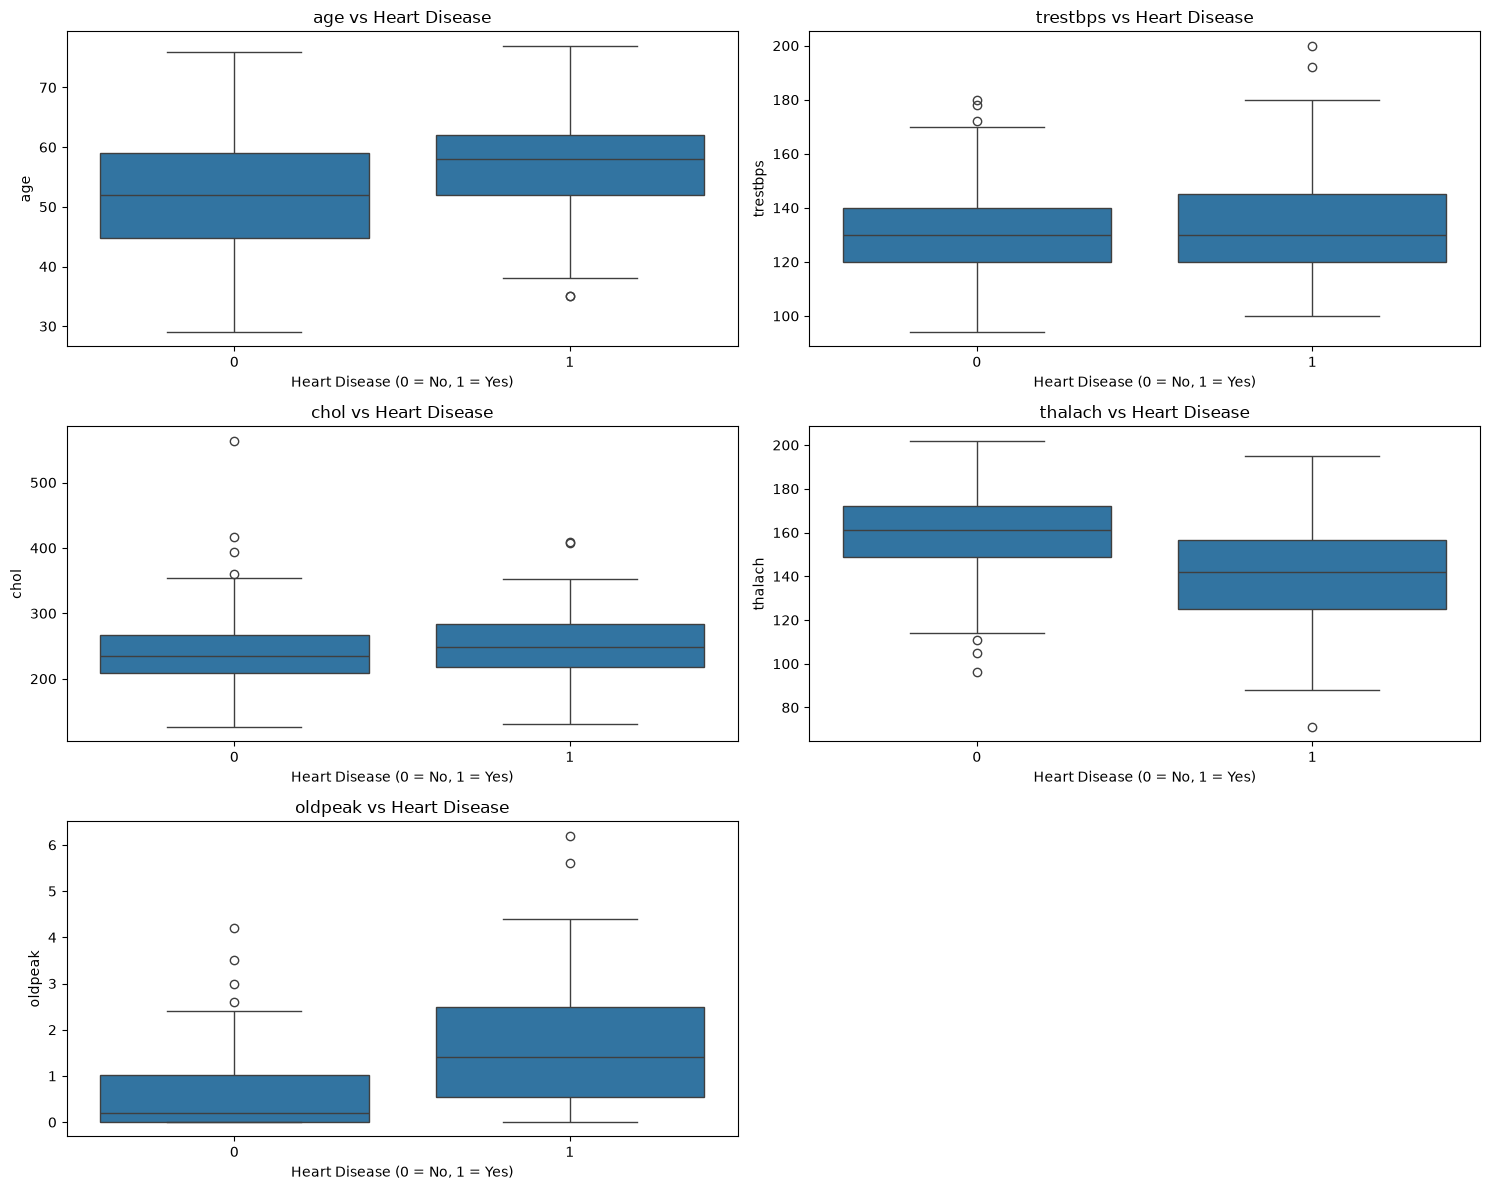

In [32]:
# Numerical features for feature-target analysis
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Plot each numerical feature against the binary target
plt.figure(figsize=(15, 12))

for i, feature in enumerate(numerical_features, 1):
    plt.subplot(3, 2, i)

    sns.boxplot(data=df, x="target", y=feature)

    plt.title(f"{feature} vs Heart Disease")
    plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

Boxplots were used to compare the distributions of five numerical features across the binary heart disease target classes. Age showed a higher median in the disease-positive group. Resting blood pressure and cholesterol displayed substantial overlap between classes. Maximum heart rate was lower in the disease-positive group, while Oldpeak showed a higher median and wider distribution in that group. These observations suggest that Oldpeak and maximum heart rate may provide useful predictive information. However, conclusions are based on visual exploration, and the predictive contribution of each feature will be evaluated later using machine learning models.

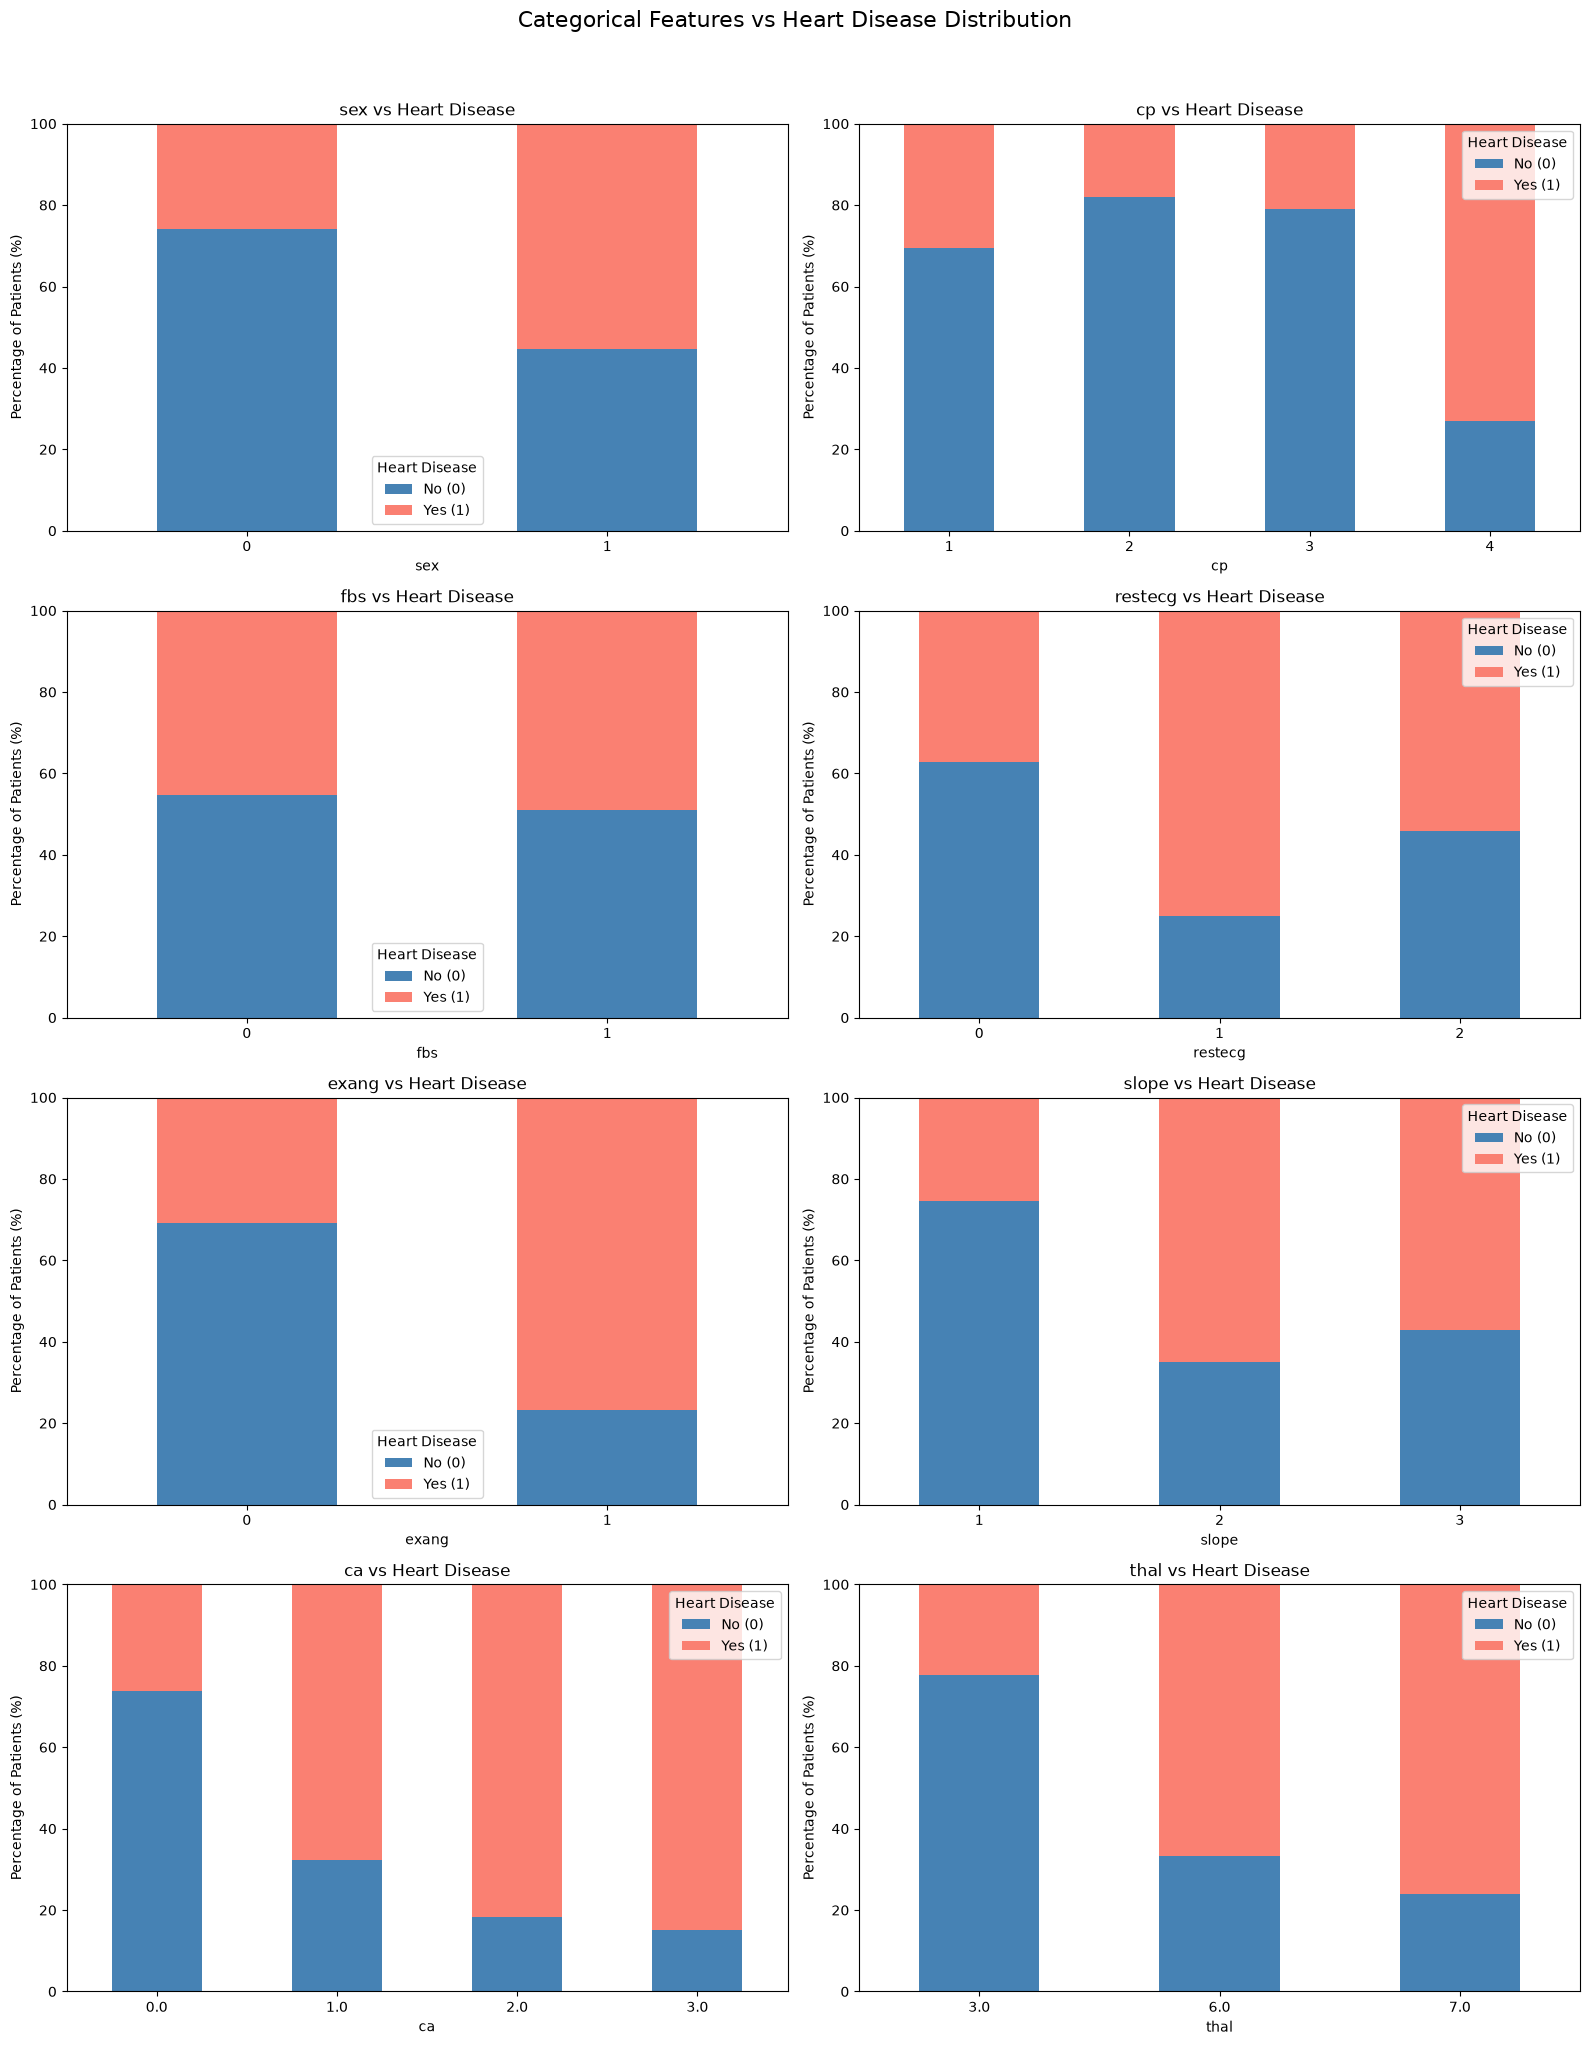

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Categorical features
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

# Create a figure with 8 subplots
fig, axes = plt.subplots(4, 2, figsize=(16, 20))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    # Calculate percentage distribution of target within each category
    proportions = pd.crosstab(
        df[feature],
        df["target"],
        normalize="index"
    ) * 100

    # Plot stacked percentage bars
    proportions.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        color=["steelblue", "salmon"]
    )

    axes[i].set_title(f"{feature} vs Heart Disease")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Percentage of Patients (%)")
    axes[i].legend(
        title="Heart Disease",
        labels=["No (0)", "Yes (1)"]
    )

    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis="x", rotation=0)

plt.suptitle(
    "Categorical Features vs Heart Disease Distribution",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

In [34]:
# Numerical feature statistics grouped by target
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

numerical_summary = df.groupby("target")[numerical_features].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)

display(numerical_summary)

age                      trestbps                          ...  \
         mean median   std min max     mean median    std  min  max  ...   
target                                                               ...   
0       52.59   52.0  9.51  29  76   129.25  130.0  16.20   94  180  ...   
1       56.63   58.0  7.94  35  77   134.57  130.0  18.77  100  200  ...   

       thalach                        oldpeak                         
          mean median    std min  max    mean median   std  min  max  
target                                                                
0       158.38  161.0  19.20  96  202    0.59    0.2  0.78  0.0  4.2  
1       139.26  142.0  22.59  71  195    1.57    1.4  1.30  0.0  6.2  

[2 rows x 25 columns]

In [35]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

for feature in categorical_features:

    summary = df.groupby(feature)["target"].agg(
        Count="count",
        Heart_Disease_Cases="sum",
        Heart_Disease_Percentage="mean"
    )

    summary["Heart_Disease_Percentage"] *= 100

    summary = summary.round(2)

    print(f"\n{'=' * 50}")
    print(f"Feature: {feature}")
    print(f"{'=' * 50}")

    display(summary)


Feature: sex


,Count,Heart_Disease_Cases,Heart_Disease_Percentage
sex,,,
0,97,25,25.77
1,206,114,55.34



Feature: cp


,Count,Heart_Disease_Cases,Heart_Disease_Percentage
cp,,,
1,23,7,30.43
2,50,9,18.00
3,86,18,20.93
4,144,105,72.92



Feature: fbs


,Count,Heart_Disease_Cases,Heart_Disease_Percentage
fbs,,,
0,258,117,45.35
1,45,22,48.89


... (6 outputs left out)


Feature: ca


,Count,Heart_Disease_Cases,Heart_Disease_Percentage
ca,,,
0.0,176,46,26.14
1.0,65,44,67.69
2.0,38,31,81.58
3.0,20,17,85.00



Feature: thal


,Count,Heart_Disease_Cases,Heart_Disease_Percentage
thal,,,
3.0,166,37,22.29
6.0,18,12,66.67
7.0,117,89,76.07


In [36]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
target      0
dtype: int64

In [37]:
# Fill missing values using median
df['ca'] = df['ca'].fillna(df['ca'].median())

df['thal'] = df['thal'].fillna(df['thal'].median())

# Check missing values again
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
target      0
dtype: int64


In [38]:
print("Total missing values:", df.isnull().sum().sum())

print(df[['ca', 'thal']].isnull().sum())

Total missing values: 0
ca      0
thal    0
dtype: int64


In [39]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [40]:
# Numerical features to check for outliers
numerical_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"\nFeature: {col}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Number of Outliers: {len(outliers)}")


Feature: age
Lower Bound: 28.50
Upper Bound: 80.50
Number of Outliers: 0

Feature: trestbps
Lower Bound: 90.00
Upper Bound: 170.00
Number of Outliers: 9

Feature: chol
Lower Bound: 115.00
Upper Bound: 371.00
Number of Outliers: 5

Feature: thalach
Lower Bound: 84.75
Upper Bound: 214.75
Number of Outliers: 1

Feature: oldpeak
Lower Bound: -2.40
Upper Bound: 4.00
Number of Outliers: 5


In [41]:
# Independent features
X = df.drop(columns=['num', 'target'])

# Dependent target
y = df['target']

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [43]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (242, 13)
Testing features: (61, 13)

Training target distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
target
0    33
1    28
Name: count, dtype: int64


In [44]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

In [45]:
categorical_features = [
    "cp",
    "restecg",
    "slope",
    "thal"
]

In [46]:
binary_features = [
    "sex",
    "fbs",
    "exang"
]

discrete_features = [
    "ca"
]

In [47]:
from pathlib import Path

data_path = Path("../data/processed.cleveland.data")

print("File exists:", data_path.exists())
print("File path:", data_path.resolve())

File exists: True
File path: C:\Users\Archit Uniyal\OneDrive\Desktop\HeartGuard-AI\data\processed.cleveland.data


In [48]:
import pandas as pd

In [49]:
# Define column names
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

# Load dataset
df = pd.read_csv(
    data_path,
    names=columns,
    na_values="?"
)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [50]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [51]:
# Count missing values in each column
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [52]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary[missing_summary["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage
ca,4,1.320132
thal,2,0.660066


In [53]:
# Count duplicate rows
df.duplicated().sum()

np.int64(0)

In [54]:
# Count each target class
df["num"].value_counts().sort_index()

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [55]:
# Target distribution in percentage
(df["num"].value_counts().sort_index() / len(df) * 100).round(2)

num
0    54.13
1    18.15
2    11.88
3    11.55
4     4.29
Name: count, dtype: float64

In [56]:
target_check = pd.DataFrame({
    "Count": df["num"].value_counts().sort_index(),
    "Percentage": (df["num"].value_counts(normalize=True).sort_index() * 100).round(2)
})

target_check

,Count,Percentage
num,,
0,164,54.13
1,55,18.15
2,36,11.88
3,35,11.55
4,13,4.29


In [57]:
df["target"] = (df["num"] > 0).astype(int)

df[["num", "target"]].head(10)

,num,target
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0
5,0,0
6,3,1
7,0,0
8,2,1
9,1,1


In [58]:
df["target"].value_counts().sort_index()

target
0    164
1    139
Name: count, dtype: int64

In [59]:
(df["target"].value_counts(normalize=True).sort_index() * 100).round(2)

target
0    54.13
1    45.87
Name: proportion, dtype: float64

In [60]:
# Separate features and target

X = df.drop(columns=["num", "target"])
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (303, 13)
Target shape: (303,)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [61]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (242, 13)
X_test: (61, 13)
y_train: (242,)
y_test: (61,)


In [62]:
# Compare class distribution across original, training, and testing sets

distribution = pd.DataFrame({
    "Full Dataset": y.value_counts(normalize=True),
    "Training Set": y_train.value_counts(normalize=True),
    "Testing Set": y_test.value_counts(normalize=True)
}).sort_index() * 100

distribution.round(2)

,Full Dataset,Training Set,Testing Set
target,,,
0,54.13,54.13,54.1
1,45.87,45.87,45.9


In [63]:
# Numerical features
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Categorical features
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))

Numerical features: 5
Categorical features: 8
Total features: 13


In [64]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [65]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [66]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

Why handle_unknown="ignore"?

Suppose the model sees a category during testing that it did not encounter during training. Instead of raising an error, the encoder handles that unseen category safely by producing zeros for that feature's encoded columns.

In [67]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [68]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [69]:
preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [70]:
# Inspect learned numerical preprocessing parameters

numeric_imputer = preprocessor.named_transformers_["num"].named_steps["imputer"]
numeric_scaler = preprocessor.named_transformers_["num"].named_steps["scaler"]

numeric_parameters = pd.DataFrame({
    "Feature": numerical_features,
    "Imputation Median": numeric_imputer.statistics_,
    "Scaler Mean": numeric_scaler.mean_,
    "Scaler Std": numeric_scaler.scale_
})

numeric_parameters.round(2)

,Feature,Imputation Median,Scaler Mean,Scaler Std
0,age,56.0,54.55,8.98
1,trestbps,130.0,130.96,17.59
2,chol,244.5,249.84,52.74
3,thalach,153.5,149.96,22.64
4,oldpeak,0.8,1.00,1.12


In [72]:
# Inspect learned categorical preprocessing parameters

categorical_imputer = (
    preprocessor.named_transformers_["cat"]
    .named_steps["imputer"]
)

categorical_encoder = (
    preprocessor.named_transformers_["cat"]
    .named_steps["encoder"]
)

categorical_parameters = pd.DataFrame({
    "Feature": categorical_features,
    "Imputation Value": categorical_imputer.statistics_,
    "Learned Categories": [
        categories.tolist()
        for categories in categorical_encoder.categories_
    ]
})

categorical_parameters

,Feature,Imputation Value,Learned Categories
0,sex,1.0,"[0.0, 1.0]"
1,cp,4.0,"[1.0, 2.0, 3.0, 4.0]"
2,fbs,0.0,"[0.0, 1.0]"
3,restecg,0.0,"[0.0, 1.0, 2.0]"
4,exang,0.0,"[0.0, 1.0]"
5,slope,1.0,"[1.0, 2.0, 3.0]"
6,ca,0.0,"[0.0, 1.0, 2.0, 3.0]"
7,thal,3.0,"[3.0, 6.0, 7.0]"


In [73]:
# Transform training and testing data
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (242, 28)
Processed testing shape: (61, 28)


In [74]:
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))
print(feature_names)

Total transformed features: 28
['num__age' 'num__trestbps' 'num__chol' 'num__thalach' 'num__oldpeak'
 'cat__sex_0.0' 'cat__sex_1.0' 'cat__cp_1.0' 'cat__cp_2.0' 'cat__cp_3.0'
 'cat__cp_4.0' 'cat__fbs_0.0' 'cat__fbs_1.0' 'cat__restecg_0.0'
 'cat__restecg_1.0' 'cat__restecg_2.0' 'cat__exang_0.0' 'cat__exang_1.0'
 'cat__slope_1.0' 'cat__slope_2.0' 'cat__slope_3.0' 'cat__ca_0.0'
 'cat__ca_1.0' 'cat__ca_2.0' 'cat__ca_3.0' 'cat__thal_3.0' 'cat__thal_6.0'
 'cat__thal_7.0']


In [75]:
from scipy.sparse import issparse

# Select first 5 transformed rows
sample_data = X_train_processed[:5]

# Convert to dense array if sparse
if issparse(sample_data):
    sample_data = sample_data.toarray()

# Create readable DataFrame
processed_sample = pd.DataFrame(
    sample_data,
    columns=feature_names
)

processed_sample.round(2)

,num__age,num__trestbps,num__chol,num__thalach,num__oldpeak,cat__sex_0.0,cat__sex_1.0,cat__cp_1.0,cat__cp_2.0,cat__cp_3.0,...,cat__slope_1.0,cat__slope_2.0,cat__slope_3.0,cat__ca_0.0,cat__ca_1.0,cat__ca_2.0,cat__ca_3.0,cat__thal_3.0,cat__thal_6.0,cat__thal_7.0
0,-0.73,-0.40,0.46,0.71,-0.45,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.05,-0.05,0.23,0.22,-0.89,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.06,0.06,0.72,0.40,-0.89,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-0.06,-1.31,1.12,0.27,-0.89,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.27,0.51,-0.17,-1.19,-0.71,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [76]:
import numpy as np
from scipy.sparse import issparse

# Convert to dense arrays for validation if sparse
train_array = (
    X_train_processed.toarray()
    if issparse(X_train_processed)
    else X_train_processed
)

test_array = (
    X_test_processed.toarray()
    if issparse(X_test_processed)
    else X_test_processed
)

print("Train contains NaN:", np.isnan(train_array).any())
print("Test contains NaN:", np.isnan(test_array).any())

print("Train contains Inf:", np.isinf(train_array).any())
print("Test contains Inf:", np.isinf(test_array).any())

print("Train shape:", train_array.shape)
print("Test shape:", test_array.shape)

Train contains NaN: False
Test contains NaN: False
Train contains Inf: False
Test contains Inf: False
Train shape: (242, 28)
Test shape: (61, 28)


In [77]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_processed, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [78]:
y_pred = model.predict(X_test_processed)

print("Predictions:", y_pred)

Predictions: [0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 1 1 1 1 1 1 0 1 0 1 0 0 1 0 1 0 1 1 1 0 1 0
 0 0 1 1 1 1 1 0 0 1 0 1 0 0 1 0 0 0 1 1 1 0 0 1]


In [79]:
import pandas as pd

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
0,0,0
1,0,1
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,1,1
9,0,0


In [80]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")

Accuracy: 0.8852
Accuracy Percentage: 88.52%


In [81]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[28  5]
 [ 2 26]]


In [82]:
from sklearn.metrics import precision_score, recall_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall * 100:.2f}%)")

Precision: 0.8387 (83.87%)
Recall:    0.9286 (92.86%)


In [83]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)

print(f"F1 Score: {f1:.4f}")
print(f"F1 Percentage: {f1 * 100:.2f}%")

F1 Score: 0.8814
F1 Percentage: 88.14%


In [84]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [85]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models defined successfully!")
print(list(models.keys()))

Models defined successfully!
['Logistic Regression', 'Random Forest', 'Gradient Boosting']


In [86]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation is ready!")

5-Fold Stratified Cross-Validation is ready!


In [87]:
from sklearn.model_selection import cross_validate
from sklearn.base import clone

scoring = ["accuracy", "precision", "recall", "f1"]

cv_results = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results[name] = scores

    print(f"{name} completed!")

Logistic Regression completed!
Random Forest completed!
Gradient Boosting completed!


In [88]:
import pandas as pd

comparison_data = []

for name, scores in cv_results.items():
    comparison_data.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean()
    })

model_comparison = pd.DataFrame(comparison_data)

model_comparison.sort_values(
    by="F1 Mean",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean
0,Logistic Regression,0.847109,0.009977,0.876753,0.783399,0.824501
1,Random Forest,0.818112,0.030707,0.817253,0.782609,0.794756
2,Gradient Boosting,0.797534,0.023946,0.772387,0.792490,0.780894


In [89]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


In [90]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

xgb_scores = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)

print("XGBoost Cross-Validation Results")
print("-" * 35)

print(f"Accuracy:  {xgb_scores['test_accuracy'].mean():.4f}")
print(f"Precision: {xgb_scores['test_precision'].mean():.4f}")
print(f"Recall:    {xgb_scores['test_recall'].mean():.4f}")
print(f"F1 Score:  {xgb_scores['test_f1'].mean():.4f}")

XGBoost Cross-Validation Results
-----------------------------------
Accuracy:  0.7895
Precision: 0.7723
Recall:    0.7747
F1 Score:  0.7707


In [91]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Accuracy": [0.8471, 0.8181, 0.7895],
    "Precision": [0.8868, 0.8173, 0.7723],
    "Recall": [0.7833, 0.7826, 0.7747],
    "F1 Score": [0.8245, 0.7948, 0.7707]
})

comparison = comparison.sort_values(by="Accuracy", ascending=False)

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8471,0.8868,0.7833,0.8245
1,Random Forest,0.8181,0.8173,0.7826,0.7948
2,XGBoost,0.7895,0.7723,0.7747,0.7707


In [92]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(rf_grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Best Cross-Validation ROC-AUC:
0.9026


In [93]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])

xgb_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.01, 0.1],
    "classifier__subsample": [0.8, 1.0]
}

xgb_grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

xgb_grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(xgb_grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(xgb_grid_search.best_score_, 4))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters:
{'classifier__learning_rate': 0.01, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}

Best Cross-Validation ROC-AUC:
0.8839


In [94]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

lr_auc_scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Logistic Regression CV ROC-AUC")
print("Fold Scores:", lr_auc_scores)
print("Mean ROC-AUC:", round(lr_auc_scores.mean(), 4))
print("Std:", round(lr_auc_scores.std(), 4))

Logistic Regression CV ROC-AUC
Fold Scores: [0.9180602  0.90909091 0.88986014 0.91433566 0.88111888]
Mean ROC-AUC: 0.9025
Std: 0.0144


In [95]:
print("Random Forest")
rf_best_index = rf_grid_search.best_index_
print("Mean ROC-AUC:", round(rf_grid_search.cv_results_["mean_test_score"][rf_best_index], 4))
print("Std ROC-AUC:", round(rf_grid_search.cv_results_["std_test_score"][rf_best_index], 4))

print("\nXGBoost")
xgb_best_index = xgb_grid_search.best_index_
print("Mean ROC-AUC:", round(xgb_grid_search.cv_results_["mean_test_score"][xgb_best_index], 4))
print("Std ROC-AUC:", round(xgb_grid_search.cv_results_["std_test_score"][xgb_best_index], 4))

print("\nLogistic Regression")
print("Mean ROC-AUC:", round(lr_auc_scores.mean(), 4))
print("Std ROC-AUC:", round(lr_auc_scores.std(), 4))

Random Forest
Mean ROC-AUC: 0.9026
Std ROC-AUC: 0.0256

XGBoost
Mean ROC-AUC: 0.8839
Std ROC-AUC: 0.02

Logistic Regression
Mean ROC-AUC: 0.9025
Std ROC-AUC: 0.0144


In [96]:
from sklearn.model_selection import cross_validate
import pandas as pd

models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest (Tuned)": rf_grid_search.best_estimator_,
    "XGBoost (Tuned)": xgb_grid_search.best_estimator_
}

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

performance = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    performance[name] = {
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    }

performance_matrix = pd.DataFrame(performance).T

performance_matrix = performance_matrix.round(4)

performance_matrix

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.8471,0.8768,0.7834,0.8245,0.9025
Random Forest (Tuned),0.8139,0.8188,0.7735,0.7902,0.9026
XGBoost (Tuned),0.8179,0.8426,0.7553,0.7899,0.8812


In [97]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Define the three models
test_models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest (Tuned)": rf_grid_search.best_estimator_,
    "XGBoost (Tuned)": xgb_grid_search.best_estimator_
}

test_results = {}

for name, model in test_models.items():

    # Train on the complete training set
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    test_results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

# Create comparison matrix
test_performance = pd.DataFrame(test_results).T

test_performance = test_performance.round(4)

test_performance

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
Random Forest (Tuned),0.8852,0.8621,0.8929,0.8772,0.9459
XGBoost (Tuned),0.8689,0.8333,0.8929,0.8621,0.9372


In [98]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

# Generate out-of-fold probabilities using Logistic Regression
oof_probabilities = cross_val_predict(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("OOF probabilities generated:", len(oof_probabilities))
print("First 10 probabilities:", oof_probabilities[:10])

OOF probabilities generated: 242
First 10 probabilities: [0.82584705 0.08616387 0.445766   0.25003767 0.57882778 0.95313652
 0.99313163 0.93199568 0.0344015  0.99467301]


In [99]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (oof_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_train, y_pred_threshold).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, y_pred_threshold),
        "Precision": precision_score(y_train, y_pred_threshold),
        "Recall": recall_score(y_train, y_pred_threshold),
        "F1 Score": f1_score(y_train, y_pred_threshold),
        "False Negatives": fn,
        "False Positives": fp
    })

threshold_df = pd.DataFrame(threshold_results).round(4)

threshold_df

,Threshold,Accuracy,Precision,Recall,F1 Score,False Negatives,False Positives
0,0.3,0.7851,0.7153,0.8829,0.7903,13,39
1,0.4,0.8347,0.8087,0.8378,0.8230,18,22
2,0.5,0.8471,0.8700,0.7838,0.8246,24,13
3,0.6,0.8306,0.8804,0.7297,0.7980,30,11
4,0.7,0.8264,0.9059,0.6937,0.7857,34,8


In [101]:
%pip install shap

     -------------------------------------- 554.9/554.9 kB 5.0 MB/s eta 0:00:00
     ---------------------------------------- 80.2/80.2 kB 2.2 MB/s eta 0:00:00
     ---------------------------------------- 2.8/2.8 MB 7.5 MB/s eta 0:00:00
     ---------------------------------------- 41.9/41.9 MB 2.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [102]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [103]:
# Extract fitted components
fitted_preprocessor = lr_pipeline.named_steps["preprocessor"]
fitted_lr = lr_pipeline.named_steps["classifier"]

# Transform training data
X_train_transformed = fitted_preprocessor.transform(X_train)

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

print("Model:", fitted_lr)
print("Transformed data shape:", X_train_transformed.shape)
print("Number of feature names:", len(feature_names))
print("\nFeatures:")
print(feature_names)

Model: LogisticRegression(max_iter=1000, random_state=42)
Transformed data shape: (242, 28)
Number of feature names: 28

Features:
['num__age' 'num__trestbps' 'num__chol' 'num__thalach' 'num__oldpeak'
 'cat__sex_0.0' 'cat__sex_1.0' 'cat__cp_1.0' 'cat__cp_2.0' 'cat__cp_3.0'
 'cat__cp_4.0' 'cat__fbs_0.0' 'cat__fbs_1.0' 'cat__restecg_0.0'
 'cat__restecg_1.0' 'cat__restecg_2.0' 'cat__exang_0.0' 'cat__exang_1.0'
 'cat__slope_1.0' 'cat__slope_2.0' 'cat__slope_3.0' 'cat__ca_0.0'
 'cat__ca_1.0' 'cat__ca_2.0' 'cat__ca_3.0' 'cat__thal_3.0' 'cat__thal_6.0'
 'cat__thal_7.0']


In [104]:
# Create SHAP explainer for Logistic Regression
explainer = shap.LinearExplainer(
    fitted_lr,
    X_train_transformed
)

# Calculate SHAP values
shap_values = explainer(X_train_transformed)

print("SHAP values calculated successfully!")
print("SHAP values shape:", shap_values.values.shape)

SHAP values calculated successfully!
SHAP values shape: (242, 28)


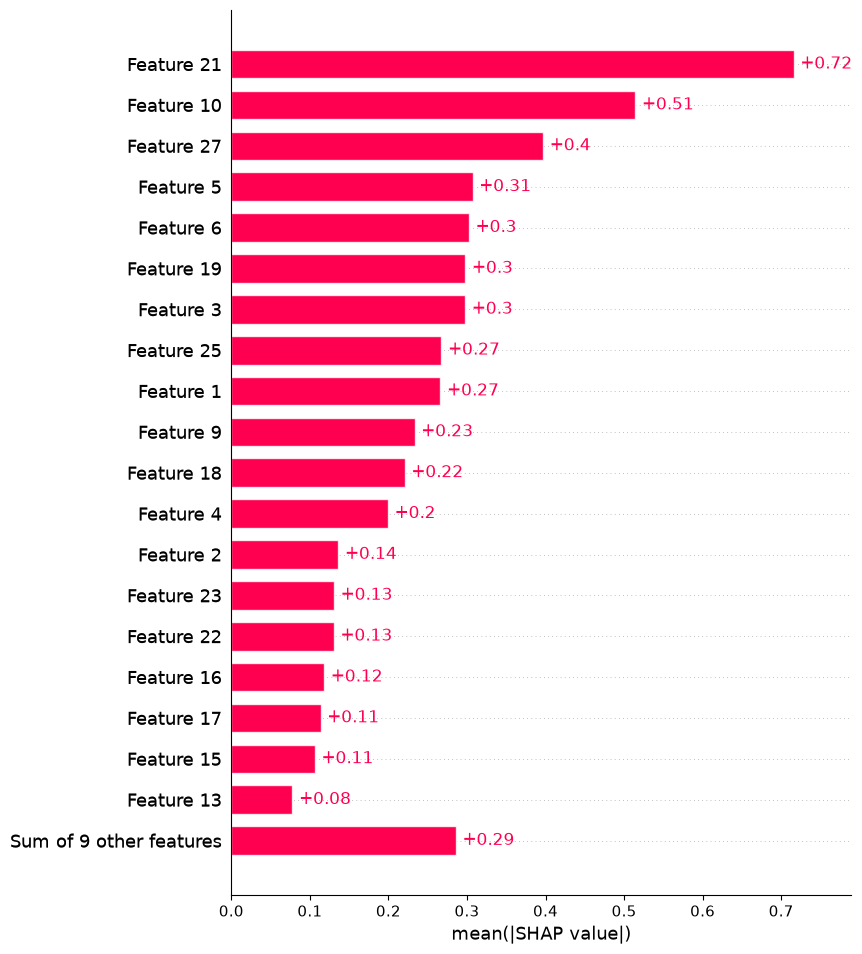

In [105]:
# Global SHAP feature importance
shap.plots.bar(shap_values, max_display=20)

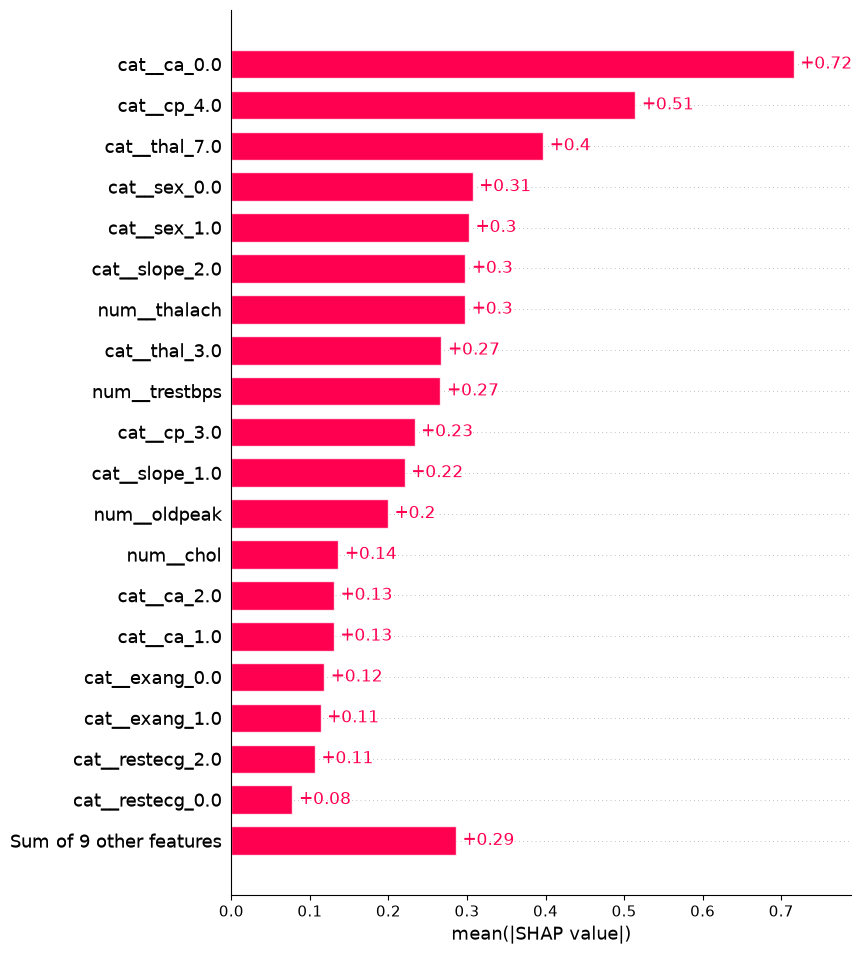

In [106]:
import pandas as pd

# Convert transformed data into a DataFrame with feature names
X_train_shap = pd.DataFrame(
    X_train_transformed,
    columns=feature_names
)

# Recreate explainer with named features
explainer = shap.LinearExplainer(
    fitted_lr,
    X_train_shap
)

# Recalculate SHAP values
shap_values = explainer(X_train_shap)

# Generate feature importance plot
shap.plots.bar(shap_values, max_display=20)

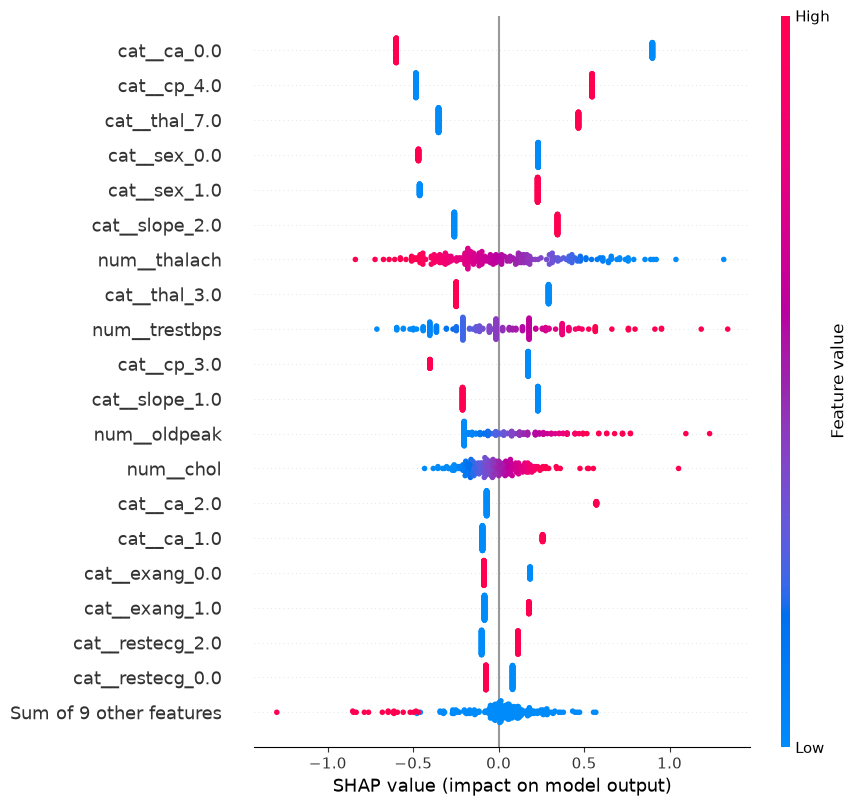

In [107]:
shap.plots.beeswarm(shap_values, max_display=20)

c:\Users\Archit Uniyal\OneDrive\Desktop\HeartGuard-AI\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\Archit Uniyal\OneDrive\Desktop\HeartGuard-AI\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


Actual Class: 1
Predicted Class: 1
Probability of Heart Disease: 0.7801


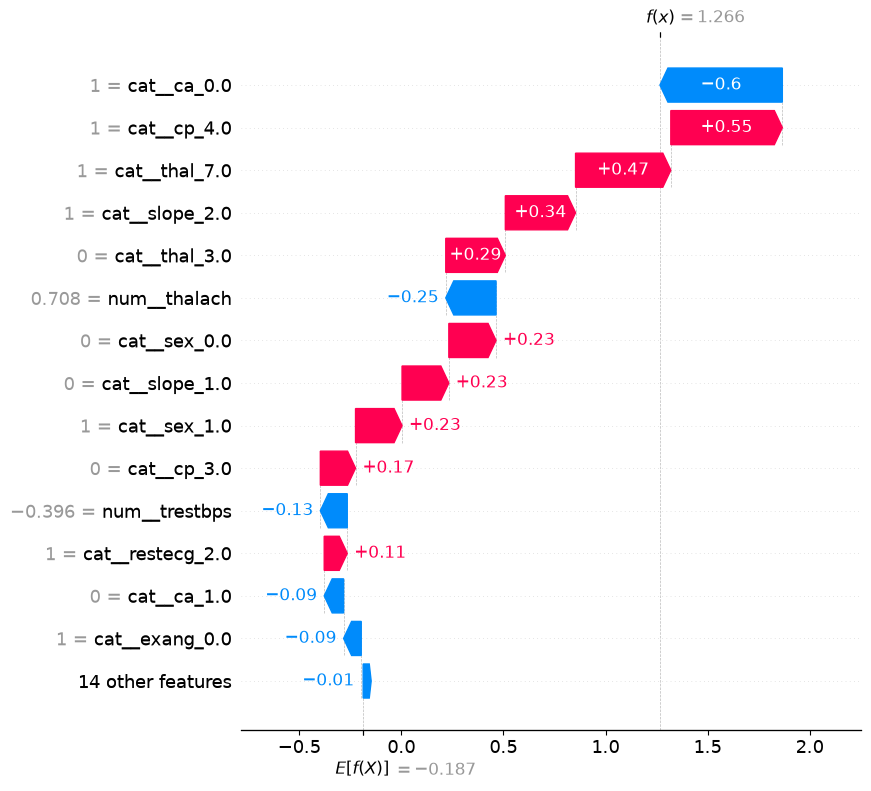

In [108]:
sample_index = 0

# Select one patient
sample = X_train_shap.iloc[[sample_index]]

# Actual class
actual = y_train.iloc[sample_index]

# Model prediction
prediction = fitted_lr.predict(sample)[0]

# Predicted probability
probability = fitted_lr.predict_proba(sample)[0, 1]

print("Actual Class:", actual)
print("Predicted Class:", prediction)
print("Probability of Heart Disease:", round(probability, 4))

# SHAP Waterfall Plot
shap.plots.waterfall(shap_values[sample_index], max_display=15)

In [109]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [110]:
import joblib
from pathlib import Path

# Create model directory if it doesn't exist
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save the complete pipeline
model_path = model_dir / "heartguard_model.joblib"

joblib.dump(final_model, model_path)

print(f"Model saved successfully at: {model_path}")

Model saved successfully at: models\heartguard_model.joblib


In [111]:
import joblib

# Load the saved model
loaded_model = joblib.load("models/heartguard_model.joblib")

# Predict on test data
test_predictions = loaded_model.predict(X_test)
test_probabilities = loaded_model.predict_proba(X_test)[:, 1]

print("Model loaded successfully!")
print("First 5 predictions:", test_predictions[:5])
print("First 5 probabilities:", test_probabilities[:5].round(4))

Model loaded successfully!
First 5 predictions: [0 1 0 0 0]
First 5 probabilities: [0.2093 0.6015 0.0215 0.0333 0.3118]
